本笔记本使用 2012-01 至 2024-12 的训练数据，检查七个因子的 Pearson 相关性矩阵和方差膨胀因子（VIF）。经核对，候选因子为五个月度变量和两个年度变量，本次使用全部七项。2025–2026 年留作后续预测评估。

政策事件 dummy 和 USDSLE 不进入因子矩阵。铁矿石出口先使用原版数据；由于原版保留了长期填充，随后用 `NO_FILL` 版本替换同一因子进行敏感性检查。两个铁矿石版本分别计算。

This notebook examines Pearson correlations and variance inflation factors (VIFs) for all seven factors using the Jan 2012 to Dec 2024 training period. The selection contains five monthly variables and two annual variables. The 2025–2026 evaluation data are excluded from all diagnostics and parameter calculations.

Policy event dummies and USDSLE are excluded from the factor matrix. The original iron ore export series is used first. Its retained long fill intervals motivate a second check that replaces this factor with the `NO_FILL` version. The two versions are evaluated separately.


In [17]:
# Import the packages used throughout this notebook.
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant


先用 pandas 读取原始 CSV，再设置训练区间与检查阈值。

Read the CSV files with pandas before setting the training window and diagnostic thresholds. 

| 代码中的因子 / Factor label | 中文含义 | English definition | 原始频率 / Original frequency |
|---|---|---|---|
| Base money | 基础货币对数变化率 | Base money log change (%) | 月度 / Monthly |
| FX reserves | 外汇储备对数变化率 | FX reserves log change (%) | 月度 / Monthly |
| Fuel imports | 燃料进口对数变化率 | Fuel imports log change (%) | 月度 / Monthly |
| Food imports | 食品进口对数变化率 | Food imports log change (%) | 月度 / Monthly |
| Iron ore exports | 铁矿石出口对数变化率 | Iron ore exports log change (%) | 月度 / Monthly |
| Government debt | 政府债务/GDP 年度百分点变化 | Annual change in government debt/GDP (pp) | 年度，逐月重复 / Annual, repeated monthly |
| Current account | 经常账户/GDP 年度百分点变化 | Annual change in current account/GDP (pp) | 年度，逐月重复 / Annual, repeated monthly |


In [18]:
# Resolve data paths from either the project root or notebook directory.
DATA_DIR = Path("data/final_monthly")
if not DATA_DIR.is_dir():
    DATA_DIR = Path("../data/final_monthly")
if not DATA_DIR.is_dir():
    raise FileNotFoundError("Run from the project root or notebook directory.")

FACTOR_FILES = {
    "Base money": "base_money_log_change_monthly.csv",
    "FX reserves": "fx_reserves_log_change_monthly.csv",
    "Fuel imports": "fuel_imports_log_change_monthly.csv",
    "Food imports": "food_imports_log_change_monthly.csv",
    "Iron ore exports": "iron_ore_exports_log_change_monthly.csv",
    "Government debt": "general_government_gross_debt_annual_change_pp_monthly.csv",
    "Current account": "current_account_balance_annual_change_pp_monthly.csv",
}
NO_FILL_FILE = "NO_FILL_iron_ore_exports_log_change_monthly.csv"


下面保留每个 CSV 的原始 DF，便于检查列名和追溯来源。备用铁矿石数据单独读取，之后仅用于替换检查。

Keep each CSV as a raw DataFrame so that column names and sources remain traceable. Read the alternative iron ore series separately for the later replacement check.


In [19]:
# Load raw CSVs before cleaning, alignment, or diagnostic calculations.
raw_frames = {
    factor: pd.read_csv(DATA_DIR / filename)
    for factor, filename in FACTOR_FILES.items()
}
raw_iron_no_fill = pd.read_csv(DATA_DIR / NO_FILL_FILE)

display(pd.DataFrame({
    "source_file": FACTOR_FILES,
    "value_column": {key: Path(value).stem for key, value in FACTOR_FILES.items()},
}).rename_axis("factor"))


,source_file,value_column
factor,,
Base money,base_money_log_change_monthly.csv,base_money_log_change_monthly
FX reserves,fx_reserves_log_change_monthly.csv,fx_reserves_log_change_monthly
Fuel imports,fuel_imports_log_change_monthly.csv,fuel_imports_log_change_monthly
Food imports,food_imports_log_change_monthly.csv,food_imports_log_change_monthly
Iron ore exports,iron_ore_exports_log_change_monthly.csv,iron_ore_exports_log_change_monthly
Government debt,general_government_gross_debt_annual_change_pp...,general_government_gross_debt_annual_change_pp...
Current account,current_account_balance_annual_change_pp_month...,current_account_balance_annual_change_pp_monthly


固定训练日期和提示阈值：`|r| ≥ 0.80` 提示较强的双变量线性相关；`VIF ≥ 5` 提示存在较为明显的共线性，`VIF ≥ 10` 提示因子之间有严重的共线性，需要进行处理。

Set fixed training dates and warning thresholds: `|r| ≥ 0.80` indicates a strong bivariate linear correlation; `VIF ≥ 5` indicates fairly evident collinearity; and `VIF ≥ 10` indicates severe collinearity among factors that requires treatment.

In [20]:
# Set all sample and screening choices before processing observations.
TRAIN_START = pd.Timestamp("2012-01-31")
TRAIN_END = pd.Timestamp("2024-12-31")
EXPECTED_FACTOR_COUNT = 7
CORR_WARNING = 0.80
VIF_WARNING = 5.0
VIF_HIGH = 10.0
RUN_NO_FILL_CHECK = True

train_months = pd.date_range(TRAIN_START, TRAIN_END, freq="ME", name="date")
assert len(FACTOR_FILES) == EXPECTED_FACTOR_COUNT
assert TRAIN_END < pd.Timestamp("2025-01-01")
assert 0 < CORR_WARNING < 1 and 1 < VIF_WARNING < VIF_HIGH


先按日期截取训练期，再转换数值，检查重复月份并按月末对齐。

Filter to the training period before converting values, checking duplicate months, and aligning month-end dates. 

In [21]:
# filter data within the training calendar and return series
def training_series(frame, value_column):
    'Extract one numeric series on the training calendar.'
    dates = pd.to_datetime(frame["date"], format="%Y-%m-%d", errors="raise")
    in_train = dates.between(TRAIN_START, TRAIN_END)
    train = frame.loc[in_train, [value_column]].copy()
    train.index = pd.DatetimeIndex(dates.loc[in_train], name="date")
    if train.index.has_duplicates:
        raise ValueError(f"Duplicate training dates: {value_column}")
    if not train.index.is_month_end.all():
        raise ValueError(f"Expected month-end training dates: {value_column}")
    values = pd.to_numeric(train[value_column], errors="raise").astype(float)
    return values.replace([np.inf, -np.inf], np.nan).reindex(train_months)


# Extract only the explicitly named factor columns.
train_factors = pd.DataFrame({
    factor: training_series(raw_frames[factor], Path(filename).stem)
    for factor, filename in FACTOR_FILES.items()
})
iron_no_fill = training_series(raw_iron_no_fill, Path(NO_FILL_FILE).stem)


数据表报告训练期的有效月份、缺失月份、零变化和不同取值数量。零变化可以是真实结果，不能仅凭零值判定填充。两项年度因子的每年取值应保持一致；重复到各月不会增加年度信息量。

The audit reports valid months, missing months, zero changes, and distinct values within the training window. A zero change can be a real observation and alone does not identify a filled value. Each annual factor should be constant within a year; monthly repetition adds no annual information.


In [22]:
quality = pd.DataFrame({
    "training_months": len(train_months),
    "valid_months": train_factors.notna().sum(),
    "missing_months": train_factors.isna().sum(),
    "zero_changes": train_factors.eq(0).sum(),
    "distinct_values": train_factors.nunique(),
    "first_valid": train_factors.apply(lambda s: s.first_valid_index()),
    "last_valid": train_factors.apply(lambda s: s.last_valid_index()),
}).rename_axis("factor")
display(quality)

# Validate annual repetition without treating repeated rows as new annual data.
annual_factors = ["Government debt", "Current account"]
annual_unique = train_factors[annual_factors].groupby(train_factors.index.year).nunique()
if annual_unique.gt(1).any().any():
    raise ValueError("An annual factor changes within a year; inspect the source.")
print(f"Training calendar: {len(train_months)} months; annual periods: {len(annual_unique)}")


,training_months,valid_months,missing_months,zero_changes,distinct_values,first_valid,last_valid
factor,,,,,,,
Base money,156,156,0,1,156,2012-01-31,2024-12-31
FX reserves,156,156,0,0,156,2012-01-31,2024-12-31
Fuel imports,156,156,0,0,156,2012-01-31,2024-12-31
Food imports,156,156,0,0,156,2012-01-31,2024-12-31
Iron ore exports,156,156,0,41,116,2012-01-31,2024-12-31
Government debt,156,156,0,12,12,2012-01-31,2024-12-31
Current account,156,156,0,0,13,2012-01-31,2024-12-31


Training calendar: 156 months; annual periods: 13


相关性矩阵和 VIF 统一使用七个因子均非缺失的月份。这样每个相关系数的样本与 VIF 完全一致。[pandas 的 `corr`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.corr.html) 默认使用每一对变量的非缺失行，因此这里先对整张因子表删除不完整行。

Use months with complete observations for all seven factors for both correlation and VIF. This gives every correlation coefficient the same sample as the VIF calculation. Since pandas `corr` uses pairwise complete observations by default, incomplete rows are removed from the full factor table first.


In [23]:
def complete_sample(frame):
    'Keep common finite rows and reject undefined diagnostic inputs.'
    sample = frame.replace([np.inf, -np.inf], np.nan).dropna().copy()
    if len(sample) <= sample.shape[1] + 1:
        raise ValueError("Too few complete rows for the factor matrix and intercept.")
    constant = sample.columns[sample.nunique().le(1)].tolist()
    if constant:
        raise ValueError(f"Constant factors have undefined correlation/VIF: {constant}")
    if not sample.index.to_series().between(TRAIN_START, TRAIN_END).all():
        raise ValueError("A diagnostic sample contains dates outside training.")
    return sample


baseline_sample = complete_sample(train_factors)
print(f"Baseline: {len(baseline_sample)} complete months, {baseline_sample.shape[1]} factors")
print(f"Dates: {baseline_sample.index.min():%Y-%m} to {baseline_sample.index.max():%Y-%m}")
print(f"Dropped training months: {len(train_factors) - len(baseline_sample)}")


Baseline: 156 complete months, 7 factors
Dates: 2012-01 to 2024-12
Dropped training months: 0


Pearson 相关系数描述两个因子的线性关联，范围为 $[-1, 1]$。正负号表示方向，绝对值表示强度。较低的两两相关仍可能伴随多变量的线性依赖，需要继续检查 VIF。

Pearson correlation measures pairwise linear association on $[-1, 1]$. Its sign gives direction and its absolute value gives strength. Low pairwise correlations can coexist with dependence on a combination of other variables, which motivates the VIF check.


In [24]:
def correlation_pairs(matrix):
    'Return each off-diagonal pair once, ordered by absolute correlation.'
    rows = []
    for i, factor_a in enumerate(matrix.columns):
        for factor_b in matrix.columns[i + 1:]:
            r = matrix.loc[factor_a, factor_b]
            rows.append({"factor_a": factor_a, "factor_b": factor_b, "r": r})
    pairs = pd.DataFrame(rows)
    pairs["abs_r"] = pairs["r"].abs()
    pairs["review"] = pairs["abs_r"].ge(CORR_WARNING)
    return pairs.sort_values("abs_r", ascending=False).reset_index(drop=True)


corr_matrix = baseline_sample.corr(method="pearson")
corr_pairs = correlation_pairs(corr_matrix)
display(corr_matrix.round(3))



,Base money,FX reserves,Fuel imports,Food imports,Iron ore exports,Government debt,Current account
Base money,1.000,0.476,-0.051,-0.015,-0.111,-0.004,0.023
FX reserves,0.476,1.000,-0.061,-0.015,-0.056,-0.053,0.022
Fuel imports,-0.051,-0.061,1.000,0.088,0.059,-0.025,0.070
Food imports,-0.015,-0.015,0.088,1.000,0.130,0.016,0.005
Iron ore exports,-0.111,-0.056,0.059,0.130,1.000,-0.008,0.072
Government debt,-0.004,-0.053,-0.025,0.016,-0.008,1.000,-0.035
Current account,0.023,0.022,0.070,0.005,0.072,-0.035,1.000


热力图使用固定的 −1 至 1 色阶，并在格内标注相关系数。坐标轴使用上表中的英文名称，便于在不同系统上显示。

The heatmap uses a fixed scale from −1 to 1 and annotates each coefficient. Axis labels use the English names listed above for consistent display across systems.


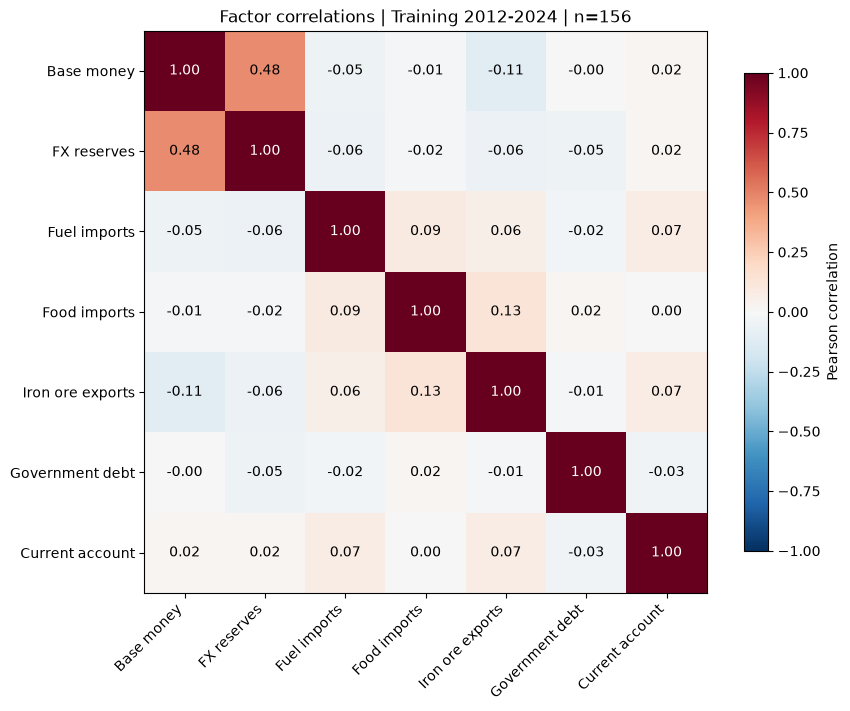

In [ ]:
# plot heatmap of correlation matrix
def plot_correlation(matrix, title):
    'Plot a labelled correlation matrix with a fixed colour scale.'
    fig, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)
    chart = ax.imshow(matrix, cmap="RdBu_r", vmin=-1, vmax=1)
    ticks = np.arange(len(matrix))
    ax.set_xticks(ticks, labels=matrix.columns, rotation=45, ha="right")
    ax.set_yticks(ticks, labels=matrix.index)
    for i in ticks:
        for j in ticks:
            value = matrix.iloc[i, j]
            colour = "white" if abs(value) > 0.60 else "black"
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", color=colour)
    ax.set_title(title)
    fig.colorbar(chart, ax=ax, label="Pearson correlation", shrink=0.85)
    plt.show()


plot_correlation(corr_matrix, f"Factor correlations | Training 2012-2024 | n={len(baseline_sample)}")


对每个因子 $X_j$，以其余六个因子和截距为解释变量进行辅助回归，得到 $R_j^2$：

$$\mathrm{VIF}_j = \frac{1}{1-R_j^2}, \qquad \mathrm{Tolerance}_j = 1-R_j^2.$$

VIF 接近 1 表示该因子与其他因子的线性关系较弱；VIF 越大，系数方差因这种关系而膨胀的程度越高。先用当前训练样本的均值和标准差进行标准化，再加入截距。该缩放改善数值计算，同时保留含截距回归的 VIF。

For each factor $X_j$, regress it on the other six factors and an intercept to obtain $R_j^2$. VIF measures variance inflation associated with linear dependence on the other factors. Values near 1 indicate little inflation. Standardize using the current training sample, then include an intercept. This scaling improves numerical stability and preserves VIF for regressions with an intercept. 


In [ ]:
def vif_table(sample):
    'Calculate centered VIFs using auxiliary regressions with an intercept.'
    scaled = (sample - sample.mean()) / sample.std(ddof=0)
    design = add_constant(scaled, has_constant="add").to_numpy(dtype=float)
    # Large or infinite VIFs remain visible in the output.
    with np.errstate(divide="ignore", invalid="raise"):
        values = [variance_inflation_factor(design, j + 1) for j in range(sample.shape[1])]
    result = pd.DataFrame({"VIF": values}, index=sample.columns)
    result["tolerance"] = 1 / result["VIF"]
    result["auxiliary_R2"] = 1 - result["tolerance"]
    result["review"] = result["VIF"].ge(VIF_WARNING)
    result["level"] = np.select(
        [result["VIF"].ge(VIF_HIGH), result["review"]],
        ["high", "review"], default="below threshold",
    )
    return result.rename_axis("factor").sort_values("VIF", ascending=False)


baseline_vif = vif_table(baseline_sample)
display(baseline_vif.round(4))


,VIF,tolerance,auxiliary_R2,review,level
factor,,,,,
Base money,1.3070,0.7651,0.2349,False,below threshold
FX reserves,1.2999,0.7693,0.2307,False,below threshold
Iron ore exports,1.0373,0.9641,0.0359,False,below threshold
Food imports,1.0246,0.9760,0.0240,False,below threshold
Fuel imports,1.0196,0.9808,0.0192,False,below threshold
Current account,1.0123,0.9879,0.0121,False,below threshold
Government debt,1.0056,0.9945,0.0055,False,below threshold


同时检查含截距矩阵的秩。满秩表示当前矩阵没有完全线性依赖。

Also check the rank of the matrix including the intercept. Full rank rules out exact linear dependence in the current matrix.


In [27]:
def sample_summary(sample, vif):
    'Summarize coverage, correlations, and the rank of the scaled design.'
    scaled = (sample - sample.mean()) / sample.std(ddof=0)
    design = add_constant(scaled, has_constant="add").to_numpy(dtype=float)
    pairs = correlation_pairs(sample.corr())
    return {
        "n_months": len(sample),
        "start": sample.index.min().strftime("%Y-%m"),
        "end": sample.index.max().strftime("%Y-%m"),
        "missing_calendar_months": len(train_months.difference(sample.index)),
        "design_rank": np.linalg.matrix_rank(design),
        "design_columns": design.shape[1],
        "max_abs_r": pairs["abs_r"].max(),
        "flagged_pairs": int(pairs["review"].sum()),
        "max_VIF": vif["VIF"].max(),
        "flagged_VIFs": int(vif["review"].sum()),
    }


baseline_summary = sample_summary(baseline_sample, baseline_vif)
display(pd.DataFrame([baseline_summary], index=["Original iron ore"]).round(4))


,n_months,start,end,missing_calendar_months,design_rank,design_columns,max_abs_r,flagged_pairs,max_VIF,flagged_VIFs
Original iron ore,156,2012-01,2024-12,0,8,8,0.4759,0,1.307,0


**结果与推论 Result and Deduction**

本轮检查使用2012年1月至2024年12月的156个月度观测，共包含七个候选因子。所有双因子相关系数的绝对值均低于0.80，最高值为基础货币与外汇储备之间的0.4759。各因子的VIF介于1.0056和1.3070之间，均低于5；含截距的解释变量矩阵秩为8，与其列数一致，未发现完全线性依赖。因此，当前样本没有显示明显的多重共线性，无需基于本轮结果删除任何因子，可以继续保留七项作为候选变量。

基础货币与外汇储备呈中等正相关，可能与央行外汇交易和本币流动性投放有关。央行购入外汇并以本币支付时，外汇资产和基础货币可能同时增加；冲销操作可以抵消部分货币扩张。共同的季节性变化也可能贡献同期相关。这些是可能的经济解释，当前相关矩阵无法确认其因果关系。

本轮结果仍有两项数据限制。政府债务/GDP和经常账户/GDP的年度变化被重复至各月，156行数据仅包含13个年度观测。这不妨碍计算当前矩阵的相关系数和VIF，但低VIF不能解决年度样本较少、数据公布时间和混合频率建模的问题。政府债务变化的ADF结果仍应保留“结论不明确”的判断，在频率和信息可得时间处理完成前，两项年度指标暂不直接纳入月度基准模型。原版铁矿石出口序列保留了长期填充，训练期内有41个月的零变化，不能将完整的156行等同于156个月均有原始观测。代码虽然读取了`NO_FILL`版本，但尚未执行对应的相关矩阵和VIF计算，因此当前笔记本尚不能声称结论已通过该项敏感性检查。

The diagnostics use 156 monthly observations from January 2012 through December 2024 and include 7 candidate factors. All absolute pairwise correlations are below 0.80. The largest correlation is 0.4759 between base money and foreign exchange reserves. VIFs range from 1.0056 to 1.3070, below the threshold of 5. The design matrix, including the intercept, has rank 8 and eight columns, indicating no exact linear dependence. These results provide no evidence of substantial multicollinearity in the current sample. No factor needs to be removed on these grounds, and all seven can remain candidates.

The moderate positive correlation between base money and foreign exchange reserves may reflect central bank foreign exchange transactions and domestic liquidity creation. Purchases of foreign currency paid for with domestic currency can increase both foreign assets and base money, while sterilization can offset part of the monetary expansion. Shared seasonal patterns may also contribute to the contemporaneous correlation. These are possible explanations; the correlation matrix does not establish causality.

Two data limitations remain. The annual changes in government debt/GDP and current account/GDP are repeated across months, so 156 rows contain only 13 annual observations. This does not prevent calculation of the current correlations and VIFs, but low VIFs do not resolve the limited annual sample, publication timing, or mixed-frequency modeling issues. The government debt ADF result remains inconclusive. Both annual indicators should remain outside the monthly baseline model until their frequency and information availability are addressed. The original iron ore series retains long filled intervals and contains 41 zero-change months. Complete coverage therefore does not establish that every month has an original observation. Although the `NO_FILL` series is loaded, its correlation and VIF calculations have not been executed in this notebook, so this sensitivity check remains incomplete.
